# Семинар 13. Что будет после первой строки?
Введите «Сквозь туман мерцает свет». У модели есть только эта строка и перенос. Как она решит, с какой буквы начать следующую?

Напишем языковую модель на уровне символов. Сначала разберём один обучающий пример, затем соберём ячейку памяти и цикл чтения текста. В конце проведём два опыта: измерим, помогает ли предыдущая строка предсказывать настоящую следующую, и послушаем, как температура меняет сгенерированный стих.

In [ ]:
import gzip
import json
import math
import random
import re
from collections import Counter
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F

torch.manual_seed(13)
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_dir = Path("data")
print(device)

## Из чего состоит корпус
В выборку вошла русская классика из PoetryCorpus. Одно наблюдение — одно стихотворение. Сохранены автор, название, текст и границы строк. Взяты тексты длиной 120–6000 символов с четырьмя и более строками. Повторы с одинаковой последовательностью букв удалены. [Исходный корпус](https://github.com/IlyaGusev/PoetryCorpus/blob/7a5f70e6a46b4717f7c903671f9a6a917aee6162/datasets/corpus/all.xml)

In [ ]:
with gzip.open(data_dir / "poems.json.gz", "rt", encoding="utf-8") as source:
    poems = json.load(source)
print(len(poems), "стихотворений")
display(pd.Series(Counter(p["author"] for p in poems), name="стихотворения"))
print(poems[0]["text"][:300])

## Разбиение и алфавит
Откладываем целые произведения до нарезки на окна. Иначе почти одинаковые строки одного стихотворения попадут и в обучение, и в проверку. Приводим буквы к нижнему регистру, редкие символы заменяем одним знаком.

In [ ]:
def clean(text):
    text = text.lower().replace("ё", "е").replace("—", "-").replace("–", "-")
    return re.sub(r"[^а-я ,.!?:;()«»\n-]", "?", text)

texts = [clean(p["text"]) for p in poems]
random.Random(13).shuffle(texts)
cut = int(0.9 * len(texts))
train, valid = texts[:cut], texts[cut:]

In [ ]:
alphabet = sorted(set("".join(train)) | {"?"})
to_id = {ch: i for i, ch in enumerate(alphabet)}

def encode(text):
    return torch.tensor([to_id.get(ch, to_id["?"]) for ch in clean(text)])

print(len(train), len(valid), len(alphabet))
print(repr("".join(alphabet)))

### Одна строка глазами модели
По индексу восстанавливается исходный символ после нормализации. У переноса строки есть собственный индекс. Именно ему модель должна научиться при генерации.

In [ ]:
line = "Мороз и солнце\n"
pd.DataFrame({"символ": list(clean(line).replace("\n", "↵")), "индекс": encode(line).tolist()}).T

**Работа у доски.** В следующих трёх практических блоках код решения свёрнут. Попробуйте набрать свою реализацию в новой ячейке и выполнить проверку ниже. Чтобы сверить реализацию, раскройте код. При сквозном запуске ноутбука выполняются и свёрнутые ячейки.

## Практика · сдвиг на один символ
Из последовательности длины T+1 получаем T входов и T правильных ответов. Последняя позиция входа тоже участвует в обучении.

Напишите `make_pair(sequence)`, возвращающую пару (вход, цель). Проверьте её на строке «мороз» с переносом в конце.

In [ ]:
def make_pair(sequence):
    inputs = sequence[:-1]
    targets = sequence[1:]
    return inputs, targets

In [ ]:
x, y = make_pair("мороз\n")
display(pd.DataFrame([list(x), list(y)], index=["вход", "цель"]))
assert x[1:] == y[:-1]

## Как собрать строки разной длины в батч?
Режем каждое стихотворение на окна. Последнее окно бывает короче остальных. DataLoader вызывает наш collate_fn со списком окон. Сначала сдвигаем каждое по отдельности, затем дополняем входы и цели справа до длины самого длинного примера в батче. PAD — служебная позиция после текста. Перенос строки, напротив, настоящий символ, который нужно предсказывать.

**Напишите collate_lines самостоятельно.** Вход — список одномерных последовательностей. Выход — два LongTensor формы (B,T). Для [а,б,в] и [в,а] строки целей должны быть [б,в] и [а,PAD]. Передайте свою функцию в DataLoader через collate_fn.

In [ ]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

pad = len(alphabet)
train_ids = [encode(t) for t in train]
valid_ids = [encode(t) for t in valid]

class VerseWindows(Dataset):
    def __init__(self, poems, length=64):
        self.windows = []
        for poem in poems:
            for start in range(0, len(poem)-1, length):
                self.windows.append(poem[start:start+length+1])

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, index):
        return self.windows[index]

In [ ]:
def collate_lines(batch):
    pairs = [make_pair(sequence) for sequence in batch]
    inputs, targets = zip(*pairs)
    return (pad_sequence(inputs, batch_first=True, padding_value=pad),
            pad_sequence(targets, batch_first=True, padding_value=pad))

train_loader = DataLoader(VerseWindows(train_ids), batch_size=32, shuffle=True,
                          generator=torch.Generator().manual_seed(42), collate_fn=collate_lines)
valid_loader = DataLoader(VerseWindows(valid_ids), batch_size=32, collate_fn=collate_lines)
x, y = collate_lines([encode("река\n"), encode("сон\n")])
def show_char(i):
    return "PAD" if i == pad else repr(alphabet[i])
display(pd.DataFrame([[show_char(i) for i in row] for row in [*x, *y]],
                     index=["вход 1", "вход 2", "цель 1", "цель 2"]))
x, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)

### До первого обновления
Найдите в одном окне конец строки. Какой символ должен предсказать последний пробел перед ним? Прочитайте обе последовательности, включая последний ответ.

In [ ]:
def decode(row):
    return "".join((alphabet[i] if i != pad else "·") for i in row.tolist())

print("Вход:", repr(decode(x[0])))
print("Цель:", repr(decode(y[0])))

## Практика · четыре преобразования ячейки LSTM

На каждом шаге объединим вход $x_t$ ширины $D$ и предыдущее состояние $h_{t-1}$ ширины $H$ в вектор $z$. По одному и тому же $z$ вычислим четыре величины. У каждой своя матрица из $H$ строк и $D+H$ столбцов и свой вектор смещений:
$$i=\sigma(W_i z+b_i),\quad f=\sigma(W_f z+b_f),\quad
g=\tanh(W_g z+b_g),\quad o=\sigma(W_o z+b_o).$$

$f$ определяет, сколько старой памяти перенести. $g$ предлагает новую запись, а $i$ задаёт её долю. $o$ управляет чтением обновлённой памяти:
$$c_t=f\odot c_{t-1}+i\odot g,\qquad h_t=o\odot\tanh(c_t).$$

Напишите `LSTMCell(input_size, hidden_size)` с четырьмя слоями `nn.Linear`. Метод `forward(x, state)` принимает батч входов формы `(B, D)` и пару `(h, c)` формы `(B, H)` каждый.

In [ ]:
class LSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        width = input_size + hidden_size
        self.input_gate = nn.Linear(width, hidden_size)
        self.forget_gate = nn.Linear(width, hidden_size)
        self.candidate = nn.Linear(width, hidden_size)
        self.output_gate = nn.Linear(width, hidden_size)

    def forward(self, x, state):
        h, c = state
        joined = torch.cat([x, h], dim=-1)
        i = self.input_gate(joined).sigmoid()
        f = self.forget_gate(joined).sigmoid()
        g = self.candidate(joined).tanh()
        o = self.output_gate(joined).sigmoid()
        next_c = f * c + i * g
        next_h = o * next_c.tanh()
        return next_h, next_c


class PackedLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.gates = nn.Linear(input_size + hidden_size, 4 * hidden_size)

    def forward(self, x, state):
        h, c = state
        joined = torch.cat([x, h], dim=-1)
        i, f, g, o = self.gates(joined).chunk(4, dim=-1)
        next_c = f.sigmoid() * c + i.sigmoid() * g.tanh()
        next_h = o.sigmoid() * next_c.tanh()
        return next_h, next_c

**Почему вторую запись часто используют на практике?** Все четыре слоя получают один батч $z$. Уложим $W_i,W_f,W_g,W_o$ друг под другом и в том же порядке объединим смещения. Один вызов линейного слоя вернёт сразу $4H$ чисел для каждого объекта. `chunk(4, dim=-1)` раздаст четыре блока тем же формулам. У каждого вентиля по-прежнему свои строки весов. Число обучаемых параметров в обоих случаях равно $4H(D+H+1)$.

Вместо четырёх отдельных матричных умножений выполняется одно более крупное. Это сокращает накладные расходы на запуск операций и часто позволяет полнее загрузить GPU. Фактическое ускорение зависит от ширины слоя, размера батча и устройства. Перенесём веса первой ячейки во вторую и сравним оба выхода на ненулевом батче.

In [ ]:
with torch.random.fork_rng(devices=[]), torch.no_grad():
    separate = LSTMCell(3, 2)
    packed = PackedLSTMCell(3, 2)
    projections = [separate.input_gate, separate.forget_gate, separate.candidate, separate.output_gate]
    packed.gates.weight.copy_(torch.cat([p.weight for p in projections]))
    packed.gates.bias.copy_(torch.cat([p.bias for p in projections]))

    inputs = torch.randn(4, 3)
    state = (torch.randn(4, 2), torch.randn(4, 2))
    separate_h, separate_c = separate(inputs, state)
    packed_h, packed_c = packed(inputs, state)
    torch.testing.assert_close(separate_h, packed_h)
    torch.testing.assert_close(separate_c, packed_c)
    print("Максимальное расхождение по h:", (separate_h - packed_h).abs().max().item())
    print("Максимальное расхождение по c:", (separate_c - packed_c).abs().max().item())

Проверим уравнения независимо. При нулевых весах и смещениях каждый вентиль равен 0.5, кандидат равен нулю. Из единичной памяти должна остаться половина.

In [ ]:
probe = LSTMCell(3, 2)
with torch.no_grad():
    for parameter in probe.parameters():
        parameter.zero_()
h, c = probe(torch.ones(1, 3), (torch.zeros(1, 2), torch.ones(1, 2)))
assert torch.allclose(c, torch.full_like(c, 0.5))
assert torch.allclose(h, 0.5 * c.tanh())
print(h, c)

### Что прочитает следующий шаг?
У одного элемента батча память содержит 96 чисел. Чтобы увидеть одну операцию целиком, возьмём две координаты и зададим значения вентилей после активации. Первая координата сохраняет старую запись. Во второй стираем старую запись и записываем новую. Предскажите знаки обеих координат до запуска.

In [ ]:
old = torch.tensor([0.8, 0.8])
forget = torch.tensor([0.95, 0.05])
write = torch.tensor([0.05, 0.95])
candidate = torch.tensor([-0.6, -0.6])
memory = forget * old + write * candidate
pd.DataFrame({"было": old, "перенос": forget * old, "запись": write * candidate,
              "стало": memory, "прочли при o=0.5": .5 * memory.tanh()})

## Практика · один набор весов на всю строку
Embedding превращает индекс буквы в вектор. По времени передаём состояния из одной и той же ячейки на следующий шаг. Для каждого шага линейная голова выдаёт по одному логиту на символ алфавита.

Интерфейс: `Poet(vocab_size, width=40, hidden=96)`, слои `embedding`, `cell`, `head`. Метод `forward(ids, state=None)` принимает индексы (B, T) и возвращает логиты (B, T, V) и финальную пару состояний. При отсутствии состояния начните с нулей.

Для обучения возьмём объединённую ячейку. Чтобы обучить ту же сеть с четырьмя отдельными проекциями, передайте `cell_type=LSTMCell` при создании модели.

In [ ]:
class Poet(nn.Module):
    def __init__(self, vocab_size, width=40, hidden=96, cell_type=PackedLSTMCell):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size + 1, width, padding_idx=vocab_size)
        self.cell = cell_type(width, hidden)
        self.head = nn.Linear(hidden, vocab_size)
        self.hidden = hidden

    def forward(self, ids, state=None):
        vectors = self.embedding(ids)
        if state is None:
            zeros = vectors.new_zeros(ids.shape[0], self.hidden)
            state = (zeros, zeros)
        outputs = []
        for vector in vectors.unbind(dim=1):
            state = self.cell(vector, state)
            outputs.append(state[0])
        logits = self.head(torch.stack(outputs, dim=1))
        return logits, state

In [ ]:
model = Poet(len(alphabet)).to(device)
scores, _ = model(x[:2, :5])
assert scores.shape == (2, 5, len(alphabet))
print(scores.shape)

### Проверка развёртки
Прочитаем пять букв подряд, а затем те же буквы двумя кусками. Логиты второго куска должны совпасть при переносе обоих состояний. Эта проверка ловит незаметную ошибку генератора, когда он забывает всю строку перед очередной буквой.

In [ ]:
whole, _ = model(x[:2, :5])
_, prefix_state = model(x[:2, :3])
suffix, _ = model(x[:2, 3:5], prefix_state)
torch.testing.assert_close(suffix, whole[:, 3:])
print("Вход", tuple(x[:2, :5].shape), "→ память", tuple(prefix_state[1].shape),
      "→ логиты", tuple(whole.shape))

## Обучение
Сопоставляем логиты каждой позиции с индексом следующего символа. Cross-entropy измеряем в натах на символ. Для ориентира посчитаем потерю модели, которая всегда выдаёт частоты символов обучающей выборки. Проверяем обе модели на одних фиксированных окнах из отложенных стихотворений.

In [ ]:
from itertools import islice
validation = [(a.to(device), b.to(device)) for a,b in islice(valid_loader, 8)]
n_valid = sum(int((b != pad).sum()) for _, b in validation)
counts = torch.bincount(torch.cat(train_ids), minlength=len(alphabet)).float() + 1
log_freq = (counts / counts.sum()).log().to(device)
baseline = sum(-log_freq[b[b != pad]].sum().item() for _, b in validation) / n_valid
print(f"Модель частот: {baseline:.3f}")

### Сколько можно предсказать по одной букве?
Частота пары «ст» даёт оценку вероятности «т» после «с». Соберём счётчики на обучающих стихах, добавим по единице каждой паре, нормируем каждую строку. На тех же проверочных окнах сравним эту модель с LSTM.

In [ ]:
v = len(alphabet)
counts2 = torch.ones(v, v)
for poem in train_ids:
    pair_ids = poem[:-1] * v + poem[1:]
    counts2 += torch.bincount(pair_ids, minlength=v*v).reshape(v, v)
log_pairs = (counts2 / counts2.sum(1, keepdim=True)).log().to(device)
bigram_loss = sum(-log_pairs[a[b != pad], b[b != pad]].sum().item() for a,b in validation) / n_valid
print(f"По частотам: {baseline:.2f} | по последней букве: {bigram_loss:.2f} нат/символ")

### Где лежит прогноз для второй строки?
В logits[b,t,:] лежат оценки всех букв для цели targets[b,t]. Прогноз третьей целевой буквы второй строки находится в logits[1,2,:]. Входной Embedding имеет дополнительную нулевую строку PAD. У выходного слоя только V настоящих символов: сгенерировать PAD невозможно. При вычислении ошибки ignore_index исключает фиктивные позиции из суммы и её знаменателя. Проверим оба свойства.

In [ ]:
def loss_on(inputs, targets):
    logits, _ = model(inputs)
    return F.cross_entropy(logits.flatten(0, 1), targets.flatten(), ignore_index=pad)

In [ ]:
inputs, targets = collate_lines([encode("река\n"), encode("сон\n")])
inputs, targets = inputs.to(device), targets.to(device)
scores, _ = model(inputs)
keep = targets != pad
manual = F.cross_entropy(scores[keep], targets[keep])
torch.testing.assert_close(loss_on(inputs, targets), manual)
assert scores.shape[-1] == pad
print("Цель:", show_char(targets[1,2]), "· форма прогноза:", scores[1,2].shape,
      "· настоящих позиций:", int(keep.sum()))

## Продолжаем первую строку
Один раз подаём весь префикс с переносом строки. После этого подаём по одному выбранному символу и переносим оба состояния. При температуре меньше единицы частые варианты получают больше вероятности. При температуре выше единицы распределение становится ровнее.

In [ ]:
@torch.inference_mode()
def continue_poem(model, first_line, temperature=0.8, seed=13, limit=240, greedy=False):
    if temperature <= 0 or not first_line.strip():
        raise ValueError("Нужны первая строка и положительная температура")
    model.eval()
    prefix = first_line.rstrip() + "\n"
    ids = encode(prefix)[None].to(device)
    logits, state = model(ids)
    generator = torch.Generator(device=device).manual_seed(seed)
    result = ""
    for _ in range(limit):
        probs = (logits[0, -1] / temperature).softmax(dim=0)
        token = probs.argmax().view(1) if greedy else torch.multinomial(probs, 1, generator=generator)
        result += alphabet[token.item()]
        if result.count("\n") == 4:
            break
        logits, state = model(token.view(1, 1), state)
    return prefix + result

In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=0.003)
steps = 400
history = []
first_line = "Сквозь туман мерцает свет"
def snapshot():
    return continue_poem(model, first_line, temperature=.75, seed=7, limit=120)
samples = {0: snapshot()}
batches = iter(train_loader)
for step in range(1, steps + 1):
    model.train()
    try:
        inputs, targets = next(batches)
    except StopIteration:
        batches = iter(train_loader)
        inputs, targets = next(batches)
    inputs, targets = inputs.to(device), targets.to(device)
    optimizer.zero_grad(set_to_none=True)
    loss = loss_on(inputs, targets)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    if step in (50, steps):
        samples[step] = snapshot()
    if step == 1 or step % 50 == 0:
        model.eval()
        with torch.inference_mode():
            val_loss = sum(loss_on(a, b).item() * int((b != pad).sum()) for a,b in validation) / n_valid
        history.append((step, loss.item(), val_loss))
print(f"Последняя проверка: {history[-1][2]:.3f} нат/символ")

In [ ]:
steps_seen, train_loss, valid_loss = zip(*history)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(steps_seen, train_loss, color="#a36b35", alpha=.7, label="Обучение, текущий батч")
ax.plot(steps_seen, valid_loss, "o-", color="#176779", label="Отложенные стихи")
ax.axhline(baseline, color="gray", ls="--", label="Частоты букв")
ax.set(xlabel="Обновления весов", ylabel="Cross-entropy, нат/символ")
ax.axhline(bigram_loss, color="#753858", ls=":", label="Предыдущая буква")
ax.legend()
fig.tight_layout()
plt.show()

In [ ]:
for step, text in samples.items():
    print(f"Обновлений: {step}")
    print(text, end="\n\n")

In [ ]:
first_line = "За окном затихли голоса"
for temperature in [0.65, 1.0]:
    print(f"Температура {temperature}")
    print(continue_poem(model, first_line, temperature), end="\n\n")

## Что успела выучить модель?
Для двух следующих экспериментов загрузим веса той же архитектуры после 1800 обновлений. Все продолжения получены одной моделью. В собственном эксперименте можно подставить обученную выше `model`.

In [ ]:
trained = Poet(len(alphabet)).to(device)
checkpoint = torch.load(data_dir / "poet.pt", map_location=device, weights_only=True)
assert checkpoint["alphabet"] == alphabet
# У готовой модели алфавит тот же. Добавим нулевую строку для входного PAD.
old = checkpoint["weights"]["embedding.weight"]
checkpoint["weights"]["embedding.weight"] = torch.cat([old, torch.zeros_like(old[:1])])
trained.load_state_dict(checkpoint["weights"])


### Открываем обученную ячейку
В формуле мы сами задавали значения вентилей. Теперь посмотрим, какие значения получаются при чтении настоящей строки. Для рисунка выберем координату с наибольшим размахом памяти на этом префиксе. У каждого столбца один входной символ. Найдите участок, где память накапливает отрицательные значения при открытом входе. Сравните его с участками, где ослабевает перенос. Значение c может по модулю превысить единицу: tanh ограничивает видимое h при чтении.

In [ ]:
from support.text_visuals import plot_memory_trace

text = "Сквозь туман мерцает свет\n"
with torch.inference_mode():
    ids = encode(text)[None].to(device)
    h = c = trained.embedding.weight.new_zeros(1, trained.hidden)
    gates, memories = [], []
    for vector in trained.embedding(ids).unbind(1):
        raw = trained.cell.gates(torch.cat([vector, h], dim=1))
        i, f, _, o = raw.chunk(4, dim=1)
        gates.append(torch.stack([i, f, o]).sigmoid()[:, 0])
        h, c = trained.cell(vector, (h, c))
        memories.append(c[0])
    memories = torch.stack(memories)
    coordinate = int((memories.amax(0) - memories.amin(0)).argmax())
    plot_memory_trace(text, torch.stack(gates)[:, :, coordinate].cpu().numpy(),
                      memories[:, coordinate].cpu().numpy(), coordinate)

### Помогает ли первая строка?
Для каждой пары строк из отложенного стихотворения считаем потери на первых восьми символах второй строки. В одном проходе модель читает первую строку и перенос, в другом получает только перенос. В обоих случаях при оценке очередного символа предыдущие буквы второй строки уже известны. Сравниваем одинаковые цели.

In [ ]:
@torch.inference_mode()
def next_line_loss(net, prefix, target):
    prefix_ids = encode(prefix + "\n")
    target_ids = encode(target)
    sequence = torch.cat([prefix_ids, target_ids[:-1]])[None].to(device)
    logits, _ = net(sequence)
    return F.cross_entropy(logits[0, len(prefix_ids)-1:], target_ids.to(device), reduction="sum").item()

totals = np.zeros(2)
characters = 0
for poem in valid:
    lines = poem.splitlines()
    if len(lines) >= 2 and lines[1].strip():
        target = lines[1][:8]
        totals += [next_line_loss(trained, prefix, target) for prefix in ["", lines[0]]]
        characters += len(target)
pd.Series(totals / characters, index=["только перенос", "строка и перенос"], name="нат на символ")

В контрольном запуске потеря снизилась с 2,025 до 2,009 нат на символ. На этих началах строк контекст дал небольшой средний выигрыш. В отдельной генерации модель по-прежнему может придумать слово или потерять тему.

### Максимум или случайный выбор?
Начнём с одной строки и одинаковых весов. При argmax история однозначно задаёт продолжение. При семплировании одна менее вероятная буква меняет контекст для всех следующих шагов. Найдите первое расхождение.

In [ ]:
for mode in [True, False]:
    print("argmax" if mode else "семплирование")
    print(continue_poem(trained, "На берегу уснули тени", seed=7, limit=120, greedy=mode))

### Теперь ваша строка
Введите новую строку. Сначала меняйте только температуру при одном seed, затем оставьте температуру и смените seed. Отметьте, где впервые расходятся два продолжения, как часто появляются настоящие слова и выдержана ли рифма. Модель обучалась угадывать буквы; отдельной награды за рифму в функции потерь нет.

In [ ]:
first_line = "Сквозь туман мерцает свет"
for temperature in [0.5, 0.8, 1.15]:
    print(f"Температура {temperature}")
    print(continue_poem(trained, first_line, temperature, seed=7), end="\n\n")

## Что меняет направление чтения?

В слове «дым» к букве «ы» можно прийти со стороны «д» и со стороны «м». Двунаправленный слой запускает две цепочки со своими весами. В позиции «ы» первая уже прочла «ды», вторая — «мы» в обратном проходе по слову. Склеиваем два скрытых вектора этой позиции и получаем признаки ширины $2H$. Так можно устроить RNN, GRU или LSTM. Для разметки сущностей оба контекста доступны, поскольку предложение уже дано целиком.

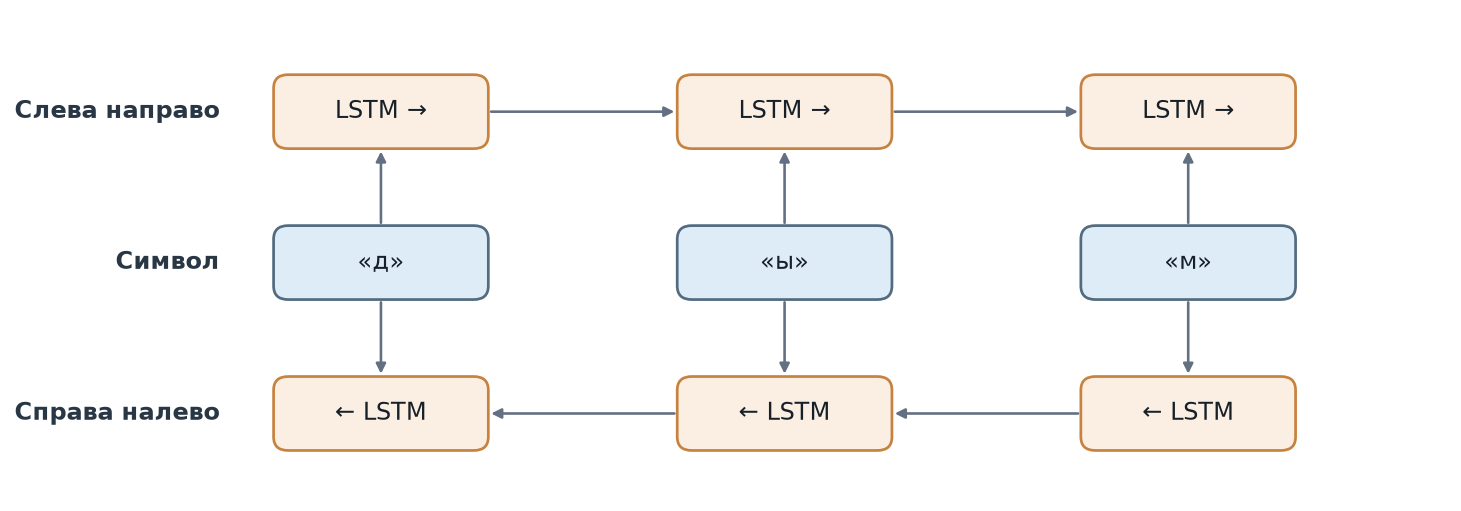

## Что меняет второй слой?

Нижняя LSTM получает эмбеддинги букв. Верхняя получает по одному скрытому вектору нижнего слоя в каждой позиции. Вертикальная стрелка передаёт $h_t^{(1)}$. Горизонтальная передаёт пару $(h,c)$ следующему шагу **своего** слоя. У каждого слоя свои веса и память. Если нижний слой двунаправленный, верхний получает склейку ширины $2H$ на каждом шаге.

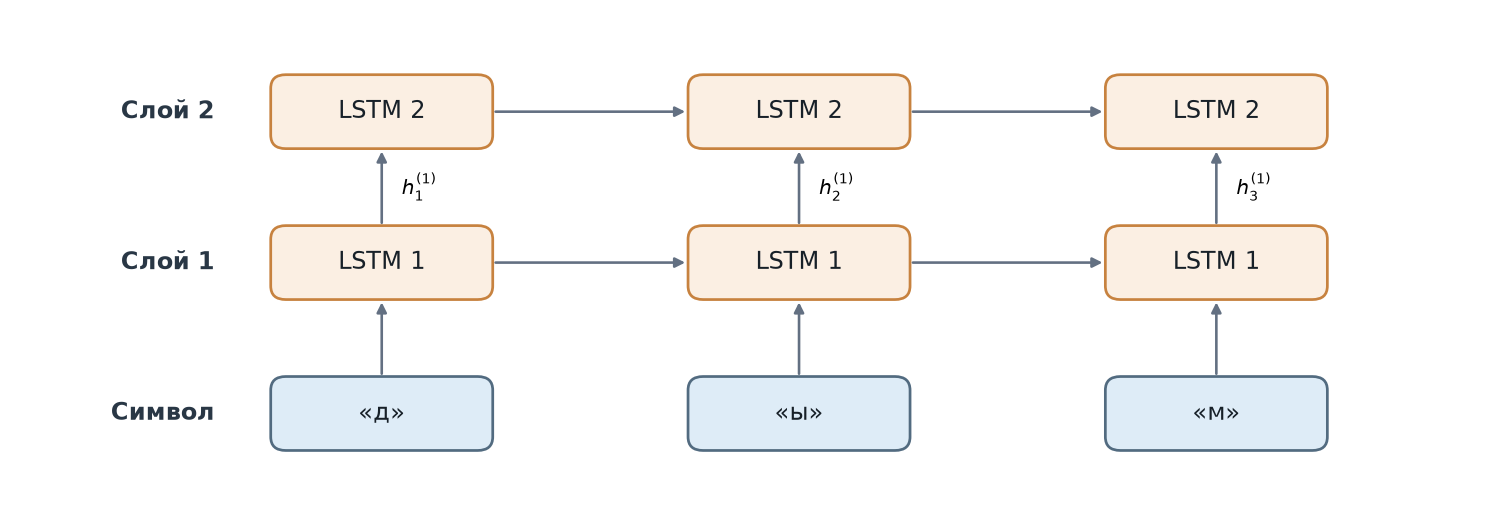

### Собираем оба варианта через PyTorch

Для прогноза после всей строки берём последние состояния верхнего слоя. У прямого направления финал приходится на последний символ, у обратного — на первый. В `h_n` PyTorch уже собрал оба финала. [Документация nn.LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html)

In [ ]:
class PrefixLSTM(nn.Module):
    def __init__(self, vocab, layers, bidirectional, width=40, hidden=64):
        super().__init__()
        self.directions = 2 if bidirectional else 1
        self.embedding = nn.Embedding(vocab, width)
        self.lstm = nn.LSTM(width, hidden, num_layers=layers, batch_first=True,
                            bidirectional=bidirectional)
        self.head = nn.Linear(hidden * self.directions, vocab)

    def forward(self, ids):
        _, (h_n, _) = self.lstm(self.embedding(ids))
        last_layer = h_n[-self.directions:]  # направления, объекты, признаки
        return self.head(last_layer.transpose(0, 1).flatten(1))

In [ ]:
example = PrefixLSTM(len(alphabet), layers=2, bidirectional=True)
letters = encode("дым")[None]
states, (ends, _) = example.lstm(example.embedding(letters))
forward, reverse = states.chunk(2, dim=-1)
assert torch.allclose(forward[:, -1], ends[-2])
assert torch.allclose(reverse[:, 0], ends[-1])
print("Все позиции:", tuple(states.shape), "Финалы двух слоёв:", tuple(ends.shape))

### Как сравнить модели на стихах?

Если дать BiLSTM всё стихотворение и попросить предсказать следующую букву **в каждой позиции**, обратная ветвь прочтёт ответы. Поэтому один пример здесь — 24 уже известных символа и одна скрытая следующая буква. Например, для начала «ды» обе ветви видят только «ды», цель — «м».

Берём окна внутри отдельных стихотворений из прежних train и validation. Обучаем четыре модели с нуля на одних и тех же батчах. На одно направление приходится 64 скрытых признака. Строки таблицы позволят отдельно сравнить ручную и готовую реализацию, глубину и добавление обратного направления.

In [ ]:
context = 24
batch_size = 64
updates = 400

def sample_prefixes(poems, count, seed):
    # Каждый допустимый старт внутри корпуса равновероятен.
    lengths = np.array([max(0, len(poem) - context) for poem in poems])
    ends = lengths.cumsum()
    offsets = np.random.default_rng(seed).integers(0, ends[-1], size=count)
    poem_ids = ends.searchsorted(offsets, side="right")
    starts = offsets - (ends - lengths)[poem_ids]
    windows = torch.stack([poems[i][j:j + context + 1] for i, j in zip(poem_ids, starts)])
    return windows[:, :-1].contiguous(), windows[:, -1].contiguous()

train_x, train_y = sample_prefixes(train_ids, updates * batch_size, seed=23)
valid_x, valid_y = sample_prefixes(valid_ids, 2048, seed=24)
print(repr(decode(valid_x[0])), "->", repr(alphabet[valid_y[0]]))

In [ ]:
from time import perf_counter

class ManualPrefix(Poet):
    def forward(self, ids):
        logits, _ = super().forward(ids)
        return logits[:, -1]

def compare_prefix_model(net):
    net = net.to(device)
    optimizer = torch.optim.AdamW(net.parameters(), lr=.003)
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = perf_counter()
    net.train()
    for inputs, targets in zip(train_x.split(batch_size), train_y.split(batch_size)):
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(net(inputs.to(device)), targets.to(device))
        loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), 1.)
        optimizer.step()
    if device.type == "cuda":
        torch.cuda.synchronize()
    seconds = perf_counter() - start

    net.eval()
    with torch.inference_mode():
        scores = torch.cat([net(x.to(device)).cpu() for x in valid_x.split(batch_size)])
        nll = F.cross_entropy(scores, valid_y).item()
        accuracy = (scores.argmax(1) == valid_y).float().mean().item()
    return [sum(p.numel() for p in net.parameters()), nll, math.exp(nll), accuracy, seconds]

In [ ]:
variants = [
    ("Своя LSTM", lambda: ManualPrefix(len(alphabet), width=40, hidden=64)),
    ("nn.LSTM, 1 слой", lambda: PrefixLSTM(len(alphabet), 1, False)),
    ("nn.LSTM, 2 слоя", lambda: PrefixLSTM(len(alphabet), 2, False)),
    ("BiLSTM, 2 слоя", lambda: PrefixLSTM(len(alphabet), 2, True)),
]
results = {}
trained_encoders = {}
for name, build in variants:
    torch.manual_seed(71)
    encoder = build()
    results[name] = compare_prefix_model(encoder)
    trained_encoders[name] = encoder
comparison = pd.DataFrame.from_dict(results, orient="index", columns=[
    "Параметры", "NLL, нат/букву", "Perplexity", "Accuracy", "Обучение, с"])
display(comparison.style.format({"NLL, нат/букву": "{:.3f}", "Perplexity": "{:.2f}",
                                 "Accuracy": "{:.1%}", "Обучение, с": "{:.1f}"}))

Accuracy засчитывает только самую вероятную букву. NLL учитывает, сколько вероятности получила правильная буква, даже если она оказалась второй. Perplexity равна $\exp(\mathrm{NLL})$ и убывает вместе с потерей. В сохранённом запуске у двухслойной LSTM perplexity составила 13.30, а при добавлении обратного направления — 12.40. Время обучения составило 15.5 и 11.6 с соответственно. У однослойной nn.LSTM perplexity равна 12.36 при времени обучения 9.8 с. Для проверки повторите опыт с несколькими инициализациями.

### Продолжим нашу строку двунаправленной моделью

После каждого выбора дописываем букву справа и заново читаем последнее окно в обе стороны. Это позволяет генерировать текст ценой повторных вычислений.

In [ ]:
@torch.inference_mode()
def continue_prefix(net, line, limit=100, temperature=.8):
    ids = encode(line + "\n").tolist()
    generator = torch.Generator().manual_seed(7)
    for _ in range(limit):
        window = torch.tensor(ids[-context:], device=device)[None]
        probabilities = (net(window)[0] / temperature).softmax(0).cpu()
        ids.append(torch.multinomial(probabilities, 1, generator=generator).item())
    return decode(torch.tensor(ids))

bidirectional_poet = trained_encoders["BiLSTM, 2 слоя"]
print(continue_prefix(bidirectional_poet, first_line))